In [6]:
import math
import numpy as np
import torch
from torch import nn
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import dl_utils

In [7]:
max_degree = 20
n_train, n_test = 100, 100
true_w = np.zeros(max_degree)
true_w[0:4] = np.array([5, 1.2, -3.4, 5.6])

features = np.random.normal(size = (n_train + n_test, 1))
np.random.shuffle(features)
poly_features = np.power(features, np.arange(max_degree).reshape(1, -1))
for i in range(max_degree):
    poly_features[:, i] /= math.gamma(i + 1)
labels = np.dot(poly_features, true_w)
labels += np.random.normal(scale=0.1, size=labels.shape)

In [8]:
true_w, features, poly_features, labels = [torch.tensor(x, dtype=
    torch.float32) for x in [true_w, features, poly_features, labels]]

features[:2], poly_features[:2, :], labels[:2]



(tensor([[-2.5714],
         [ 0.4662]]),
 tensor([[ 1.0000e+00, -2.5714e+00,  3.3061e+00, -2.8338e+00,  1.8218e+00,
          -9.3691e-01,  4.0153e-01, -1.4750e-01,  4.7412e-02, -1.3546e-02,
           3.4833e-03, -8.1429e-04,  1.7449e-04, -3.4515e-05,  6.3394e-06,
          -1.0868e-06,  1.7466e-07, -2.6419e-08,  3.7742e-09, -5.1079e-10],
         [ 1.0000e+00,  4.6623e-01,  1.0868e-01,  1.6891e-02,  1.9687e-03,
           1.8357e-04,  1.4265e-05,  9.5008e-07,  5.5369e-08,  2.8683e-09,
           1.3373e-10,  5.6680e-12,  2.2022e-13,  7.8978e-15,  2.6301e-16,
           8.1749e-18,  2.3821e-19,  6.5330e-21,  1.6921e-22,  4.1522e-24]]),
 tensor([-25.1112,   5.2882]))

In [9]:
def train(train_features, test_features, train_labels, test_labels,
          num_epochs=400):
    loss = nn.MSELoss(reduction='none')
    input_shape = train_features.shape[-1]
    net = nn.Sequential(nn.Linear(input_shape, 1, bias=False))
    batch_size = min(10, train_labels.shape[0])
    train_iter = dl_utils.load_array((train_features, train_labels.reshape(-1,1)), batch_size)
    test_iter = dl_utils.load_array((test_features, test_labels.reshape(-1,1)), batch_size, is_train=False)
    trainer = torch.optim.SGD(net.parameters(), lr=0.01)
    animator = dl_utils.Animator(xlabel='epoch', ylabel='loss', yscale='log',
                                 xlim=[1, num_epochs], ylim=[1e-3,1e2],
                                 legend=['train','test'])
    for epoch in range(num_epochs):
        dl_utils.train_epoch_ch3(net, train_iter, loss, trainer)
        if epoch == 0 or (epoch + 1) % 20 == 0:
            animator.add(epoch + 1, (dl_utils.evaluate_loss(net, train_iter, loss),
                                     dl_utils.evaluate_loss(net, test_iter, loss)))
    print('weight:', net[0].weight.data.numpy())


weight: [[ 4.9936852  1.1998173 -3.3788223  5.6113777]]


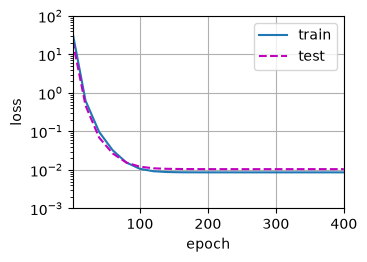

In [10]:
train(poly_features[:n_train, :4], poly_features[n_train:, :4],
      labels[:n_train], labels[n_train:])

weight: [[3.1169233 5.5704384]]


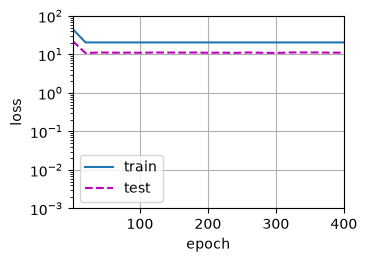

In [11]:
train(poly_features[:n_train, :2], poly_features[n_train:, :2],
      labels[:n_train], labels[n_train:])

weight: [[ 4.958051    1.3437388  -3.2574499   5.086536   -0.28383115  1.0725794
   0.450149   -0.01991025  0.21675996 -0.15340704  0.03216384 -0.09543438
  -0.1973367  -0.08415166 -0.21234058 -0.13449858 -0.07459705 -0.12896095
  -0.03044447 -0.05414861]]


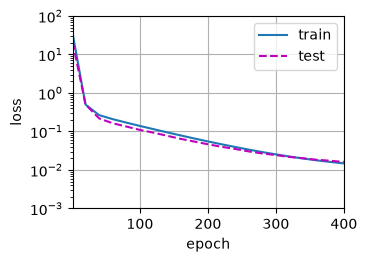

In [15]:
train(poly_features[:n_train, :], poly_features[n_train:, :],
      labels[:n_train], labels[n_train:])

weight: [[ 5.0116496   1.2604264  -3.4790802   5.263931    0.16058116  0.9682092
   0.31744704 -0.26131332  0.11150357  0.18457644  0.14555313 -0.22339308
   0.13491063  0.10807077 -0.18701747 -0.09588812  0.04607128  0.18215653
   0.03451215  0.11350021]]


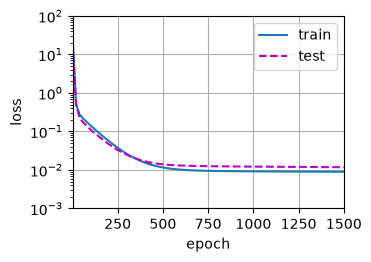

In [16]:
train(poly_features[:n_train, :], poly_features[n_train:, :],
      labels[:n_train], labels[n_train:], num_epochs=1500)